# 06 · M3 · CNN compacta desde cero: recortes, red, laboratorio y resultados

**Configuración seleccionada:** `configs/modelos/m3_cnn_fov48.yaml` (recortes de 48 mm, 96 × 96 px). Para ver la configuración inicial de 64 mm, cambia `RUTA_CFG` en la sección 1 (ver `docs/decisiones/2026-11-19_m3_campo_vision_48mm.md`).

Cuaderno de **pruebas y exploración** de M3. No sustituye a la ejecución oficial, que se lanza desde la terminal y deja
su registro en `resultados/` (ver `docs/GUIA_M3.md`):

```bash
python -m tfm_lidc.imagen --config configs/modelos/m3_cnn_fov48.yaml
```

| Sección | Qué hace | ¿Necesita GPU? |
|---|---|---|
| 1–2 | Prepara rutas y carga los recortes S2 de R1 | No |
| 3 | Galería de nódulos con el contorno de consenso | No |
| 4 | La red: capas, parámetros y tamaño de los mapas | No |
| 5 | Vista previa del aumento de datos | No |
| 6 | **Laboratorio**: entrena un pliegue con los ajustes que quieras cambiar | Recomendable (unos minutos) |
| 7 | Resultados de la ejecución completa y comparación con M0 (H1) | No |
| 8 | Errores: los falsos positivos y negativos más seguros | No |

Requisitos: entorno TFM (`pip install -e ".[dev]"`) y los recortes ya extraídos
(`python -m tfm_lidc.data.recortes --config configs/modelos/m3_cnn_fov48.yaml`).

> Si la ejecución completa está entrenando en la GPU, en la sección 6 usa `DISPOSITIVO = "cpu"` o espera a que termine:
> dos entrenamientos a la vez en MPS se ralentizan mutuamente.

## 1. Rutas y configuración

In [1]:
import os, json, pathlib, warnings
warnings.filterwarnings("ignore")
if pathlib.Path.cwd().name == "notebooks":
    os.chdir("..")
RAIZ = pathlib.Path.cwd()
print("Raíz del repositorio:", RAIZ)

import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

from tfm_lidc import config
from tfm_lidc.data import nodulos as dn, particion as dp, recortes as dr
from tfm_lidc.evaluation import agregacion, metricas
from tfm_lidc.models import cnn
from tfm_lidc import imagen

RUTA_CFG = "configs/modelos/m3_cnn_fov48.yaml"   # M3 seleccionado (48 mm); "m3_cnn.yaml" = 64 mm (sensibilidad)
cfg = config.cargar(RUTA_CFG)
DATOS = RAIZ / cfg["salidas"]["dir_resultados"] / "datos"
print("Parámetros del recorte:", dr.parametros(cfg))
print("Política de cortes:", cfg["modelo"]["entrada"]["politica"])

Raíz del repositorio: /Users/jefferson.rodriguez/Documents/UNIR_II_Cuatrimestre/TFM/tfm-lidc-xai


Parámetros del recorte: {'fov_mm': 48.0, 'mm_por_pixel': 0.5, 'ventana_hu': [-1000.0, 400.0], 'nivel_consenso': 0.5, 'tam_px': 96}
Política de cortes: S2


## 2. Nódulos, partición y recortes
Misma tabla de nódulos y misma partición versionada que M0–M2.

In [2]:
nod = dn.construir_o_cargar(cfg, DATOS)
part = dp.generar_o_cargar(nod, cfg, RAIZ)
d = part.merge(nod, on=["nodule_id", "patient_id"], validate="one_to_one")
carpeta = dr.carpeta_cache(cfg, DATOS)
X, M, man = dr.cargar(carpeta, d.nodule_id.tolist(), cfg["modelo"]["entrada"]["politica"],
                      cfg["datos"]["area_minima_corte_mm2"])
man = man.merge(d[["nodule_id", "patient_id", "etiqueta", "pliegue", "diametro_mm",
                   *[c for c in d if c.startswith("rol_")]]], on="nodule_id")
print(f"{len(d)} nódulos · {d.patient_id.nunique()} pacientes · {len(man)} cortes · tensor {X.shape} {X.dtype}")
print("Cortes por nódulo:", man.groupby("nodule_id").size().describe().round(1).to_dict())
pd.crosstab(man.pliegue, man.etiqueta, margins=True).rename(columns={0: "baja", 1: "alta"})

869 nódulos · 530 pacientes · 6070 cortes · tensor (6070, 1, 96, 96) float16
Cortes por nódulo: {'count': 869.0, 'mean': 7.0, 'std': 5.5, 'min': 1.0, '25%': 3.0, '50%': 5.0, '75%': 8.0, 'max': 45.0}


etiqueta,baja,alta,All
pliegue,,,
0,353,808,1161
1,432,913,1345
2,427,806,1233
3,406,677,1083
4,550,698,1248
All,2168,3902,6070


## 3. Galería: corte de mayor área de cada nódulo, con el contorno de consenso (rojo)
La máscara solo se usa para evaluar la explicabilidad; **nunca** entra en el modelo.

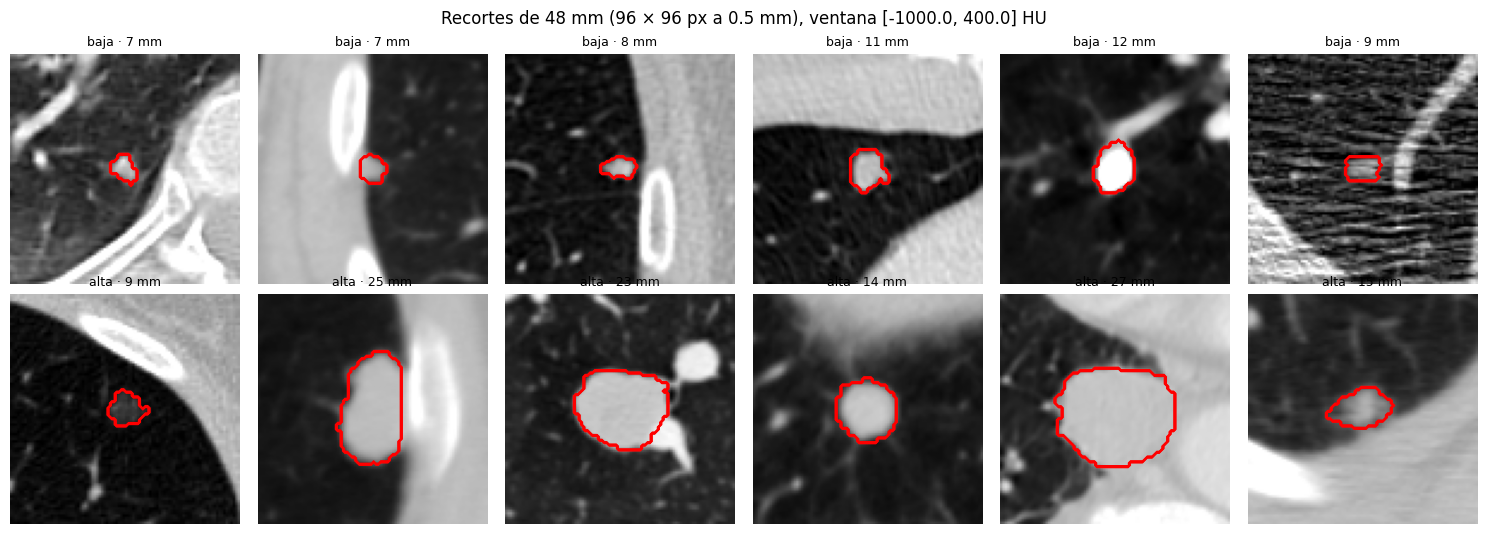

In [3]:
rng = np.random.default_rng(0)
fig, ax = plt.subplots(2, 6, figsize=(15, 5.4))
for fila, y in enumerate([0, 1]):
    ids = rng.choice(d.nodule_id[d.etiqueta == y], 6, replace=False)
    for j, nid in enumerate(ids):
        i = man.index[man.nodule_id == nid][man.area_consenso_mm2[man.nodule_id == nid].argmax()]
        ax[fila, j].imshow(X[i, -1 if X.shape[1] == 1 else 1].astype(float), cmap="gray", vmin=0, vmax=1)
        ax[fila, j].contour(M[i], colors="r", linewidths=0.8)
        ax[fila, j].set_title(f"{'alta' if y else 'baja'} · {d.set_index('nodule_id').diametro_mm[nid]:.0f} mm", fontsize=9)
        ax[fila, j].axis("off")
pr = dr.parametros(cfg)
plt.suptitle(f"Recortes de {pr['fov_mm']:g} mm ({pr['tam_px']} × {pr['tam_px']} px a {pr['mm_por_pixel']:g} mm), ventana {pr['ventana_hu']} HU"); plt.tight_layout()

## 4. La red
4 bloques de dos convoluciones 3×3. La última capa convolucional da un mapa de 12 × 12 con recortes de 96 px (16 × 16 con 128 px); en ambos casos cada celda cubre 4 mm. Es la capa que usará Grad-CAM++.

In [4]:
red = cnn.construir(cfg["modelo"], X.shape[1])
print(red)
print(f"\nParámetros entrenables: {cnn.n_parametros(red):,}")
x = torch.zeros(1, X.shape[1], *X.shape[2:])
h = x
for i, b in enumerate(red.bloques):
    h = b(h); print(f"bloque {i}: {tuple(h.shape[1:])}")
    if i < len(red.bloques) - 1:
        h = red.pool(h)
print("Salida (logit):", red.eval()(x).shape)

CNNCompacta(
  (bloques): ModuleList(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
    (2): Sequential(
    

## 5. Aumento de datos (solo en entrenamiento)
El mismo recorte con 7 aumentos aleatorios según la sección `aumento` del YAML.

Aumento: {'giros': True, 'rotacion_grados': 15, 'desplazamiento_px': 6, 'intensidad': 0.1, 'desenfoque': 0.0, 'ruido': 0.0}


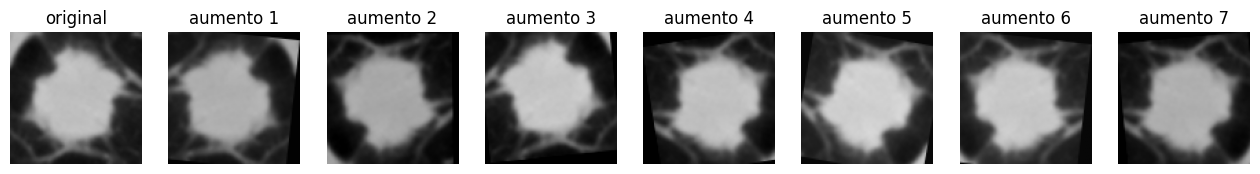

In [5]:
a = {**imagen.AUMENTO_DEF, **cfg["modelo"].get("aumento", {})}
print("Aumento:", a)
i = int(man.area_consenso_mm2.argmax())
x = torch.from_numpy(X[i:i+1].astype(np.float32)).repeat(7, 1, 1, 1)
g = torch.Generator().manual_seed(0)
xa = imagen.aumentar(x, a, g)
fig, ax = plt.subplots(1, 8, figsize=(16, 2.4))
ax[0].imshow(X[i, -1].astype(float), cmap="gray", vmin=0, vmax=1); ax[0].set_title("original")
for k in range(7):
    ax[k + 1].imshow(xa[k, -1].numpy(), cmap="gray", vmin=0, vmax=1); ax[k + 1].set_title(f"aumento {k+1}")
for e in ax: e.axis("off")

## 6. Laboratorio: entrenar un pliegue con tus ajustes

Cambia los valores de `AJUSTES` y ejecuta la celda. Se entrena con el protocolo real (`imagen.entrenar_pliegue`): mismos
roles del pliegue, parada temprana y umbral en validación, y predicción de prueba sin leer sus etiquetas.

- `EPOCAS` pequeño (3–5) para probar rápido; el YAML usa 60 con parada temprana.
- `SUBMUESTRA` (por ejemplo, 0.3) entrena con una fracción de los nódulos de entrenamiento para ir aún más rápido.
- Los resultados de un solo pliegue y pocas épocas **no** son cifras del TFM: sirven para comparar ajustes entre sí.
  Para un experimento de verdad, crea un YAML nuevo (ver la guía) y lánzalo desde la terminal.

Entrenando pliegue 0 en mps · 3937 cortes de entrenamiento

    época   0  pérdida 0.6432  AUC val 0.6259  (9.1 s)


    época   1  pérdida 0.5638  AUC val 0.8037  (7.7 s)


    época   2  pérdida 0.4951  AUC val 0.8305  (7.7 s)


    época   3  pérdida 0.4411  AUC val 0.8470  (7.9 s)



Mejor época 3 · AUC validación 0.847 · umbral 0.671
AUC de PRUEBA (pliegue 0, 159 nódulos): 0.875


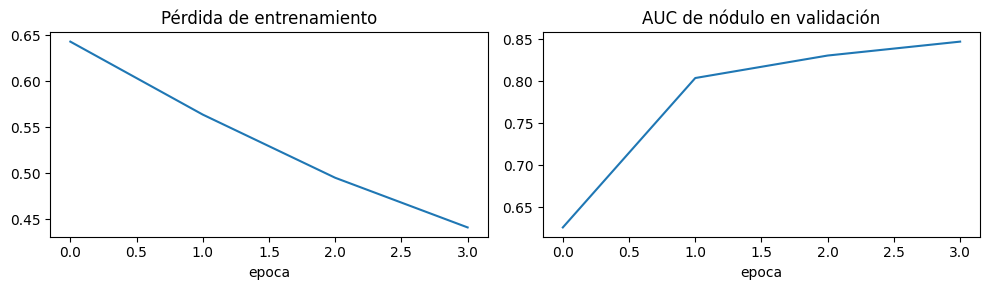

In [6]:
DISPOSITIVO = "auto"   # "auto" (mps/cuda si hay), "cpu"
PLIEGUE, SEMILLA, EPOCAS, SUBMUESTRA = 0, 42, 4, None

AJUSTES = {   # se fusionan sobre cfg["modelo"]; deja {} para usar el YAML tal cual
    "parametros":    {"anchos": [32, 64, 128, 256], "abandono": 0.3},
    "entrenamiento": {"tam_lote": 64, "tasa_aprendizaje": 1e-3, "decaimiento_pesos": 1e-4, "paciencia": 12,
                      "ponderar_por_cortes": True, "ponderar_clase": True, "agregacion": "media"},
    "aumento":       {"giros": True, "rotacion_grados": 15, "desplazamiento_px": 8, "intensidad": 0.1},
}

m_lab = config._fusionar(cfg["modelo"], AJUSTES)
rol = man[f"rol_{PLIEGUE}"].values.copy()
if SUBMUESTRA:
    tr_nod = man.nodule_id[rol == "entrenamiento"].unique()
    fuera = set(np.random.default_rng(SEMILLA).choice(tr_nod, int(len(tr_nod) * (1 - SUBMUESTRA)), replace=False))
    rol[man.nodule_id.isin(fuera).values] = "fuera"          # ni entrena ni evalúa
dev = imagen.dispositivo(DISPOSITIVO)
print(f"Entrenando pliegue {PLIEGUE} en {dev} · {np.sum(rol == 'entrenamiento')} cortes de entrenamiento")
r = imagen.entrenar_pliegue(m_lab, torch.from_numpy(X), man.nodule_id.values, man.etiqueta.values.astype(int),
                            rol, SEMILLA, dev, EPOCAS)

te = r["indices_prueba"]
p_te = agregacion.por_nodulo(man.nodule_id.values[te], r["prob_cortes_prueba"], m_lab["entrenamiento"]["agregacion"])
y_te = d.set_index("nodule_id").etiqueta.loc[p_te.index]
print(f"\nMejor época {r['mejor_epoca']} · AUC validación {r['auc_validacion']:.3f} · umbral {r['umbral']:.3f}")
print(f"AUC de PRUEBA (pliegue {PLIEGUE}, {len(p_te)} nódulos): {roc_auc_score(y_te, p_te):.3f}")
h = pd.DataFrame(r["historial"])
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
h.plot(x="epoca", y="perdida", ax=ax[0], legend=False, title="Pérdida de entrenamiento")
h.plot(x="epoca", y="auc_validacion", ax=ax[1], legend=False, title="AUC de nódulo en validación"); plt.tight_layout()

## 7. Resultados de la ejecución completa (5 pliegues × semillas)

Toma la ejecución completa más reciente de `m3_cnn` en `resultados/` y la compara con M0 (diámetro) sobre los mismos
nódulos. La comparación formal de H1 (mejor de M3–M5 frente a M0, ΔAUC pareado con IC 95 % por paciente) se hará con
el mejor modelo de imagen; aquí se muestra M3 como avance.

La tabla de ΔAUC incluye también la configuración inicial de 64 mm (`m3_cnn`) como referencia de sensibilidad.

In [7]:
def ultima(patron, completa=True):
    for c in sorted(RAIZ.glob(f"resultados/{patron}"), key=lambda p: p.stat().st_mtime, reverse=True):
        f = c / "registro.json"
        if f.exists() and (not completa or json.loads(f.read_text()).get("completo", True)):
            return c
    return None

DIR_M3, DIR_M0 = ultima(f"{cfg['modelo']['nombre']}__R1__*"), ultima("m0_diametro__R1__*")
print("M3:", DIR_M3, "\nM0:", DIR_M0)
if DIR_M3 is None:
    print("\n⚠ Aún no hay una ejecución completa de M3 (falta registro.json). Vuelve a ejecutar cuando termine.")
else:
    reg = json.loads((DIR_M3 / "registro.json").read_text())
    filas = []
    for s, v in reg["resultados_por_semilla"].items():
        filas.append({"semilla": s, **{k: f"{x['valor']:.3f} [{x['ic95'][0]:.3f}; {x['ic95'][1]:.3f}]" for k, x in v["metricas"].items()}})
    display(pd.DataFrame(filas).set_index("semilla"))
    print("AUC entre semillas:", reg["entre_semillas"])
    display(pd.DataFrame({s: v["auc_prueba_por_pliegue"] for s, v in reg["resultados_por_semilla"].items()}).rename_axis("pliegue"))
    display(pd.DataFrame({s: v["auc_por_agregacion"] for s, v in reg["resultados_por_semilla"].items()}).rename_axis("agregación"))
    display(pd.DataFrame(reg["pliegues_detalle"]).sort_values(["semilla", "pliegue"]))

M3: /Users/jefferson.rodriguez/Documents/UNIR_II_Cuatrimestre/TFM/tfm-lidc-xai/resultados/m3_cnn_fov48__R1__d9a71489d195 
M0: /Users/jefferson.rodriguez/Documents/UNIR_II_Cuatrimestre/TFM/tfm-lidc-xai/resultados/m0_diametro__R1__s42__ffae683


,auc,auprc,brier,exactitud,sensibilidad,especificidad
semilla,,,,,,
42,0.923 [0.902; 0.942],0.913 [0.880; 0.941],0.112 [0.098; 0.128],0.849 [0.821; 0.876],0.876 [0.841; 0.910],0.824 [0.780; 0.867]
43,0.919 [0.900; 0.938],0.917 [0.892; 0.940],0.114 [0.100; 0.128],0.830 [0.805; 0.854],0.839 [0.800; 0.876],0.821 [0.785; 0.857]
44,0.920 [0.900; 0.939],0.916 [0.892; 0.940],0.111 [0.097; 0.126],0.835 [0.805; 0.866],0.827 [0.780; 0.869],0.844 [0.801; 0.883]


AUC entre semillas: {'auc_media': 0.9205, 'auc_dt': 0.002}


,42,43,44
pliegue,,,
0,0.9123,0.9433,0.9157
1,0.9342,0.9317,0.9341
2,0.9258,0.9040,0.9135
3,0.9364,0.9167,0.9257
4,0.9306,0.9251,0.9296


,42,43,44
agregación,,,
media,0.9227,0.9190,0.9197
maximo,0.9256,0.9237,0.9204
media_recortada,0.9271,0.9244,0.9233


,semilla,pliegue,mejor_epoca,epocas_ejecutadas,auc_validacion,umbral,n_cortes_entrenamiento,segundos
0,42,0,7,20,0.8923,0.6077,3937,151.9
1,42,1,36,49,0.9403,0.4134,3784,352.2
2,42,2,16,29,0.9482,0.6823,3958,228.0
3,42,3,13,26,0.9129,0.3913,4093,209.5
4,42,4,22,35,0.9431,0.4345,3950,267.5
5,43,0,20,33,0.9087,0.6267,3937,260.5
6,43,1,22,35,0.9338,0.6275,3784,262.2
7,43,2,44,57,0.9495,0.5423,3958,448.3
8,43,3,18,31,0.9197,0.2840,4093,253.0
9,43,4,21,34,0.9411,0.6049,3950,264.5


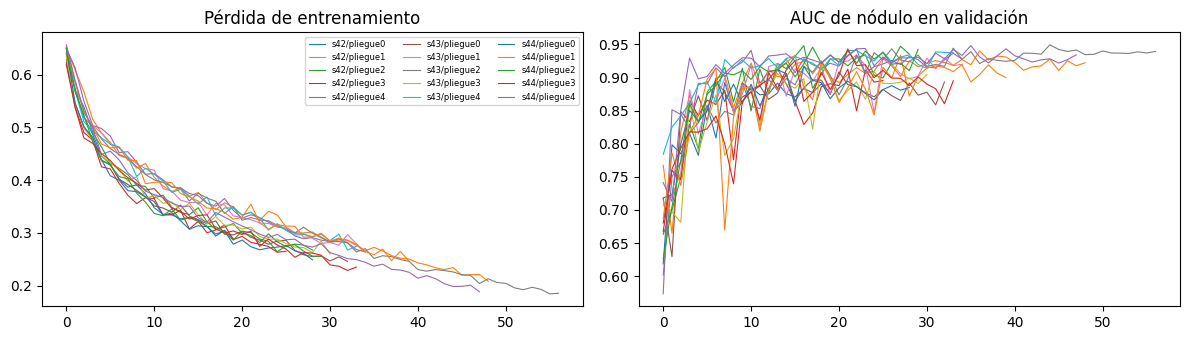

In [8]:
if DIR_M3 is not None:
    # Curvas de aprendizaje de cada (semilla, pliegue)
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    for f in sorted(DIR_M3.glob("s*/pliegue*/historial.csv")):
        h = pd.read_csv(f); et = f"{f.parent.parent.name}/{f.parent.name}"
        ax[0].plot(h.epoca, h.perdida, lw=0.8, label=et); ax[1].plot(h.epoca, h.auc_validacion, lw=0.8)
    ax[0].set_title("Pérdida de entrenamiento"); ax[1].set_title("AUC de nódulo en validación")
    ax[0].legend(fontsize=6, ncol=3); plt.tight_layout()

869 nódulos comunes · AUC M0 = 0.936 · M3 (m3_cnn_fov48): media entre semillas 0.920


,auc,delta_vs_M0,ic95,incluye_0
modelo,,,,
M3 s42,0.9227,-0.0128,[-0.031; +0.007],True
M3 s43,0.9190,-0.0165,[-0.036; +0.004],True
M3 s44,0.9197,-0.0159,[-0.037; +0.006],True
M3 ensamble,0.9336,-0.0020,[-0.019; +0.017],True
64 mm s42,0.8893,-0.0463,[-0.069; -0.022],False
64 mm s43,0.8676,-0.0680,[-0.097; -0.040],False
64 mm s44,0.9170,-0.0185,[-0.043; +0.005],True


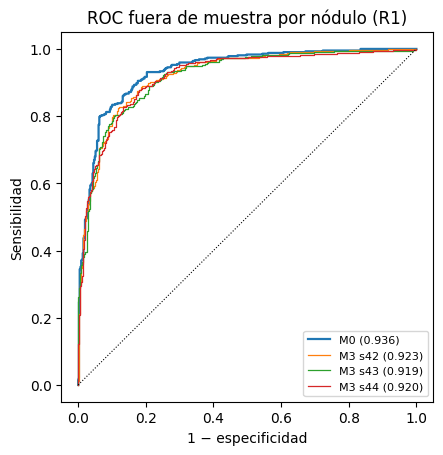

In [9]:
if DIR_M3 is not None and DIR_M0 is not None:
    m0 = pd.read_csv(DIR_M0 / "predicciones_oof.csv")[["nodule_id", "patient_id", "etiqueta", "probabilidad"]]
    oofs = {f.stem.split("_")[-1]: pd.read_csv(f) for f in sorted(DIR_M3.glob("predicciones_oof_s*.csv"))}
    base = m0.rename(columns={"probabilidad": "M0"})
    for s, o in oofs.items():                                  # una columna por semilla
        base = base.merge(o[["nodule_id", "probabilidad"]].rename(columns={"probabilidad": f"M3 {s}"}), on="nodule_id")
    DIR_64 = ultima("m3_cnn__R1__*") if cfg["modelo"]["nombre"] != "m3_cnn" else None
    if DIR_64 is not None:                                     # referencia: configuración inicial de 64 mm
        for f in sorted(DIR_64.glob("predicciones_oof_s*.csv")):
            base = base.merge(pd.read_csv(f)[["nodule_id", "probabilidad"]].rename(
                columns={"probabilidad": f"64 mm {f.stem.split('_')[-1]}"}), on="nodule_id")
    columnas_m3 = [c for c in base if c.startswith("M3 ")]
    columnas_64 = [c for c in base if c.startswith("64 mm ")]
    # Ensamble: media de las PROBABILIDADES de las semillas. Es otro modelo (3 redes promediadas), no la
    # «media de los AUC por semilla» que la memoria pide informar; se muestra solo como referencia.
    base["M3 ensamble"] = base[columnas_m3].mean(axis=1)
    y, g = base.etiqueta.values, base.patient_id.values

    def delta_auc(col, n_boot=2000, semilla=42):
        """ΔAUC pareado (col − M0) con bootstrap por paciente: mismos nódulos, mismo remuestreo para ambos."""
        pac = np.unique(g); idx = {p: np.flatnonzero(g == p) for p in pac}; rng = np.random.default_rng(semilla); dif = []
        for _ in range(n_boot):
            s_ = np.concatenate([idx[p] for p in rng.choice(pac, len(pac))])
            if len(np.unique(y[s_])) == 2:
                dif.append(roc_auc_score(y[s_], base[col].values[s_]) - roc_auc_score(y[s_], base.M0.values[s_]))
        return roc_auc_score(y, base[col]) - roc_auc_score(y, base.M0), np.percentile(dif, [2.5, 97.5])

    filas = []
    for col in [*columnas_m3, "M3 ensamble", *columnas_64]:
        d_, (lo, hi) = delta_auc(col)
        filas.append(dict(modelo=col, auc=round(roc_auc_score(y, base[col]), 4), delta_vs_M0=round(d_, 4),
                          ic95=f"[{lo:+.3f}; {hi:+.3f}]", incluye_0=bool(lo <= 0 <= hi)))
    print(f"{len(base)} nódulos comunes · AUC M0 = {roc_auc_score(y, base.M0):.3f} · "
          f"M3 ({cfg['modelo']['nombre']}): media entre semillas {np.mean([roc_auc_score(y, base[c]) for c in columnas_m3]):.3f}")
    display(pd.DataFrame(filas).set_index("modelo"))

    plt.figure(figsize=(4.8, 4.8))
    for col in ["M0", *columnas_m3]:
        fpr, tpr, _ = roc_curve(y, base[col])
        plt.plot(fpr, tpr, lw=1.6 if col == "M0" else 0.9, label=f"{col} ({roc_auc_score(y, base[col]):.3f})")
    plt.plot([0, 1], [0, 1], "k:", lw=0.8); plt.xlabel("1 − especificidad"); plt.ylabel("Sensibilidad")
    plt.legend(loc="lower right", fontsize=8); plt.title("ROC fuera de muestra por nódulo (R1)")

## 8. Errores: los nódulos peor clasificados por M3
Falsos positivos (baja sospecha con probabilidad alta) y falsos negativos (alta sospecha con probabilidad baja), con su diámetro.

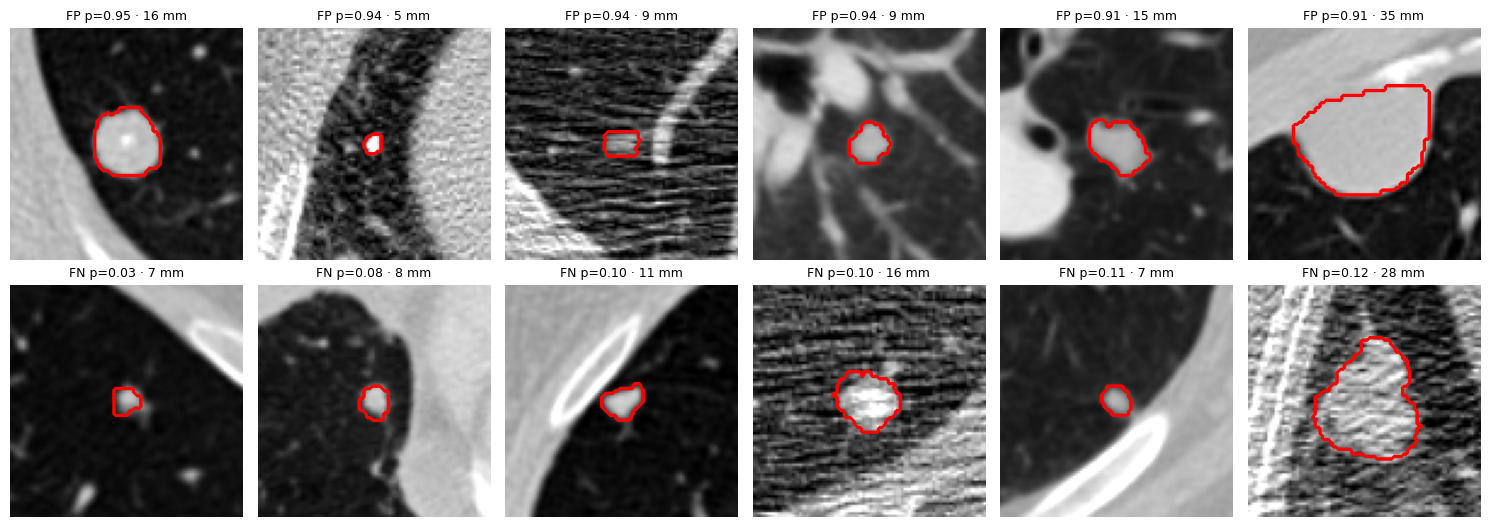

In [10]:
if DIR_M3 is not None:
    p = pd.concat(oofs.values()).groupby("nodule_id").probabilidad.mean()
    e = d.set_index("nodule_id")[["etiqueta", "diametro_mm"]].join(p)
    fp = e[e.etiqueta == 0].sort_values("probabilidad", ascending=False).head(6)
    fn = e[e.etiqueta == 1].sort_values("probabilidad").head(6)
    fig, ax = plt.subplots(2, 6, figsize=(15, 5.4))
    for fila, (tabla, nombre) in enumerate([(fp, "FP"), (fn, "FN")]):
        for j, (nid, r_) in enumerate(tabla.iterrows()):
            i = man.index[man.nodule_id == nid][man.area_consenso_mm2[man.nodule_id == nid].argmax()]
            ax[fila, j].imshow(X[i, -1].astype(float), cmap="gray", vmin=0, vmax=1)
            ax[fila, j].contour(M[i], colors="r", linewidths=0.8); ax[fila, j].axis("off")
            ax[fila, j].set_title(f"{nombre} p={r_.probabilidad:.2f} · {r_.diametro_mm:.0f} mm", fontsize=9)
    plt.tight_layout()